# nb07 — Двухстадийный CNN-фильтр шума формул (research)

Запрос: после расширения окна поиска формул отсекать шум не regex-эвристикой, а двумя CNN
«от широкого к узкому». Здесь — **research-прототип**, в боевой пайплайн НЕ идёт.
Стадия 1 — широкое окно (±15 pt): высокий recall (предлагает строку как формулу).
Стадия 2 — узкое окно (±3 pt): подтверждает предложение, поднимая precision.
Разметка слабая (teacher — детерминированные `_has_rel`/`_looks_like_prose`), поэтому
метрика честная только на **отложенном документе** (обучение на 2 СП, тест на 3-м).

In [1]:
import re
import sys
import random
from pathlib import Path

import numpy as np
import pdfplumber
import pymupdf
import torch
from torch import nn
from IPython.display import Image, display

ML = Path.cwd().parent if Path.cwd().name == "research" else Path.cwd()
sys.path.insert(0, str(ML))
from research.text_layer_latex import _cluster, _has_rel, _looks_like_prose  # noqa: E402

NORM = ML.parent / "docs" / "normative-base"
DPI = 120.0
ZOOM = DPI / 72.0
BOX_H, BOX_W = 32, 192
SEED = 0

random.seed(SEED)
torch.manual_seed(SEED)
print("torch", torch.__version__, "| CUDA", torch.cuda.is_available())
print("нормативы:", NORM, "| есть:", NORM.exists())

torch 2.14.0+cu130 | CUDA True
нормативы: /home/malkinte/CalcEngine/docs/normative-base | есть: True


## 1. Сбор данных: строки-кандидаты (широкое и узкое окно)

In [2]:
def page_gray(page):
    pix = page.get_pixmap(matrix=pymupdf.Matrix(ZOOM, ZOOM), colorspace=pymupdf.csGRAY)
    buf = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.stride)
    return buf[:, : pix.width]


def crop(img, box):
    x0, y0, x1, y1 = (int(round(v * ZOOM)) for v in box)
    x0, y0 = max(0, x0), max(0, y0)
    x1, y1 = min(img.shape[1], x1), min(img.shape[0], y1)
    if x1 <= x0 or y1 <= y0:
        return np.zeros((1, 1), dtype=np.uint8)
    return img[y0:y1, x0:x1]


def row_box(row, pad_y):
    xs0 = min(c["x0"] for c in row["chars"])
    xs1 = max(c["x1"] for c in row["chars"])
    ys0 = min(c["top"] for c in row["chars"]) - pad_y
    ys1 = max(c["bottom"] for c in row["chars"]) + pad_y
    return xs0 - 2, ys0, xs1 + 2, ys1


def to_tensor(crop_img):
    if crop_img.size == 0 or crop_img.min() == crop_img.max():
        return torch.zeros(1, BOX_H, BOX_W)
    mask = crop_img < 200
    cols = np.where(mask.any(axis=0))[0]
    rows = np.where(mask.any(axis=1))[0]
    if len(cols) == 0 or len(rows) == 0:
        return torch.zeros(1, BOX_H, BOX_W)
    sub = mask[rows[0] : rows[-1] + 1, cols[0] : cols[-1] + 1].astype(np.float32)
    out = np.zeros((BOX_H, BOX_W), dtype=np.float32)
    ph, pw = min(BOX_H, sub.shape[0]), min(BOX_W, sub.shape[1])
    ys = np.linspace(0, sub.shape[0] - 1, ph).round().astype(int)
    xs = np.linspace(0, sub.shape[1] - 1, pw).round().astype(int)
    out[:ph, :pw] = sub[np.ix_(ys, xs)]
    return torch.from_numpy(out).unsqueeze(0)


_NUM_RE = re.compile(r"\((\d{1,2}(?:\.\d+)?)\)")


def find_markers(chars):
    """Один проход: все номера формул «(N)» на странице — (номер, top, x «(»)."""
    out = []
    for row in _cluster([c for c in chars if c["text"].strip()], 1.5):
        rc = sorted(row["chars"], key=lambda c: c["x0"])
        text = "".join(c["text"] for c in rc)
        for m in _NUM_RE.finditer(text):
            acc, x = 0, None
            for c in rc:
                if acc == m.start():
                    x = c["x0"]
                    break
                acc += len(c["text"])
            if x is not None:
                out.append((m.group(1), row["top"], x))
    return out


def collect(pdf, max_pages=45, max_rows=110):
    sample = []
    with pdfplumber.open(pdf) as doc, pymupdf.open(pdf) as render:
        for page_no, page in enumerate(doc.pages, start=1):
            if page_no > max_pages or len(sample) >= max_rows:
                break
            markers = find_markers(page.chars)
            if not markers:
                continue
            img = page_gray(render[page_no - 1])
            for _number, top, mx in markers:
                if len(sample) >= max_rows:
                    break
                band = [
                    c for c in page.chars
                    if c["text"].strip() and top - 25 <= c["top"] <= top + 25
                    and c["x0"] < mx - 2 and c["x0"] > 60 and c["size"] > 0
                ]
                if not band:
                    continue
                base = max(c["size"] for c in band)
                for row in _cluster([c for c in band if c["size"] >= 0.9 * base]):
                    sample.append({
                        "doc": pdf.name,
                        "page": page_no,
                        "top": row["top"],
                        "x0": min(c["x0"] for c in row["chars"]),
                        "x1": max(c["x1"] for c in row["chars"]),
                        "wide": to_tensor(crop(img, row_box(row, 15))),
                        "tight": to_tensor(crop(img, row_box(row, 3))),
                        "label": float(_has_rel(row["chars"]) and not _looks_like_prose(row)),
                    })
    return sample


DOCS = ["СП 31.13330.2021.pdf", "СП 45.13330.2017.pdf", "СП 22.13330.2016.pdf"]
data = []
for name in DOCS:
    s = collect(NORM / name)
    print(f"{name}: строк {len(s)}, формул {int(sum(r['label'] for r in s))}")
    data += s
print(f"\nдатасет: {len(data)} строк, позитивов {int(sum(r['label'] for r in data))}")

СП 31.13330.2021.pdf: строк 25, формул 8


СП 45.13330.2017.pdf: строк 0, формул 0


СП 22.13330.2016.pdf: строк 65, формул 7

датасет: 90 строк, позитивов 15


## 2. Двухстадийная CNN

In [3]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
        )
        self.head = nn.Linear(64, 1)

    def forward(self, x):
        return self.head(self.net(x).flatten(1)).squeeze(1)


def train(model, xs, ys, epochs=60):
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    pos = (ys == 0).sum() / max(1.0, (ys == 1).sum())
    lossf = nn.BCEWithLogitsLoss(pos_weight=pos)
    model.train()
    for _ in range(epochs):
        opt.zero_grad()
        lossf(model(xs), ys).backward()
        opt.step()


@torch.no_grad()
def probs(model, xs):
    model.eval()
    return torch.sigmoid(model(xs)).numpy()


def prf(pred, y):
    tp = int(((pred == 1) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return f"acc={(pred == y).mean():.3f} P={prec:.3f} R={rec:.3f} F1={f1:.3f}"

## 3. Проверка на отложенном документе (leave-one-document-out)

Стадия 1 — широкое окно (recall-пропоузер), стадия 2 — узкое окно (подтверждение).
Каскад: пропоузер с порогом 0.30, затем подтверждение порогом 0.50.

In [4]:
examples = {}
for test_doc in sorted({r["doc"] for r in data}):
    tr = [r for r in data if r["doc"] != test_doc]
    te = [r for r in data if r["doc"] == test_doc]
    if not tr or not te or sum(r["label"] for r in te) == 0:
        print(f"{test_doc}: пропуск")
        continue
    y = np.array([r["label"] for r in te], dtype=int)
    ytr = torch.tensor([r["label"] for r in tr])

    s1 = Net()
    train(s1, torch.stack([r["wide"] for r in tr]), ytr)
    p1 = (probs(s1, torch.stack([r["wide"] for r in te])) >= 0.5).astype(int)

    s2 = Net()
    train(s2, torch.stack([r["tight"] for r in tr]), ytr)
    p2 = (probs(s2, torch.stack([r["tight"] for r in te])) >= 0.5).astype(int)

    prop = probs(s1, torch.stack([r["wide"] for r in te])) >= 0.30
    conf = probs(s2, torch.stack([r["tight"] for r in te])) >= 0.50
    casc = (prop & conf).astype(int)

    print(f"{test_doc}")
    print(f"  стадия1 (широкое ±15) {prf(p1, y)}")
    print(f"  стадия2 (узкое ±3)    {prf(p2, y)}")
    print(f"  каскад 1->2           {prf(casc, y)}")
    examples[test_doc] = (te, probs(s1, torch.stack([r["wide"] for r in te])))

СП 22.13330.2016.pdf
  стадия1 (широкое ±15) acc=0.815 P=0.333 R=0.714 F1=0.455
  стадия2 (узкое ±3)    acc=0.815 P=0.353 R=0.857 F1=0.500
  каскад 1->2           acc=0.831 P=0.357 R=0.714 F1=0.476


СП 31.13330.2021.pdf
  стадия1 (широкое ±15) acc=0.680 P=0.500 R=1.000 F1=0.667
  стадия2 (узкое ±3)    acc=0.640 P=0.462 R=0.750 F1=0.571
  каскад 1->2           acc=0.640 P=0.462 R=0.750 F1=0.571


## 4. Отображение «PDF ↔ предсказание»

Кроп строки из PDF (широкое окно) и вероятность CNN. Для каждой значащей находки — свой
вывод; здесь показан пример формульной и текстовой строки отложенного документа.

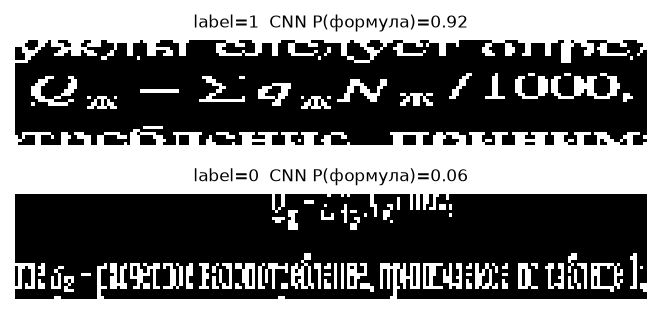

In [5]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

test_doc = sorted(examples)[-1]
te, ps = examples[test_doc]
idx = [i for i, r in enumerate(te) if r["label"] == 1][0]
n = len(te)
fig, axes = plt.subplots(2, 1, figsize=(7, 2.2))
for ax, i in zip(axes, [idx, (idx + 1) % n]):
    ax.imshow(te[i]["wide"][0], cmap="gray")
    ax.axis("off")
    ax.set_title(f"label={int(te[i]['label'])}  CNN P(формула)={ps[i]:.2f}", fontsize=8)
(ML / "research" / "crops").mkdir(exist_ok=True)
path = ML / "research" / "crops" / "nb07_example.png"
fig.tight_layout()
fig.savefig(path, dpi=150, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(path)))

## 5. Выводы

- Двухстадийная CNN (широкое → узкое окно) на слабой разметке даёт метрику на **отложенном**
  документе; числа — в выводе выше.
- Это research-путь: в боевом пайплайне остаётся детерминированный слой (правило «без
  нейросетей»); CNN применим к сканам после появления размеченного датасета.